### Лабораторная работа №1

**Выполнили:**

Мирасов Константин · ИСУ 466716 · гр. J3312

Светлов Ярослав · ИСУ 467390 · гр. J3311

### Импортируем все необходимые библиотеки

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import seaborn as sns
from scipy import integrate, optimize, stats
from statsmodels.robust.norms import HuberT, TukeyBiweight
from tqdm.auto import tqdm

#### Модель вида $X_i = \mu + \sigma U_i$

#### Распределение случайной величины $F_{U_i} = (1 - \epsilon) F_{usual}(x) + \epsilon F_{outlier}(x)$

Выберем $Z \sim N(0, 1) \quad \rightarrow \quad E[Z] = 0 \quad Var(Z) = 1$

Случайная величина $Z$ будет отвечать за обычные наблюдения в нашей модели

Выберем $W = 5T_5$

Случайная величина $W$ будет отвечать за выбросы в нашей модели

Выберем $\epsilon = 0.1$, как вероятность выбора компоненты выбросов для каждого наблюдения. Мы хотим, чтобы в модели $X_i = \mu + \sigma U_i$ параметр \sigma действительно совпадал со стандартным отклонением $X_i$, для этого необходимо $E[U] = 0, Var(U) = 1$, матожидание смеси распределений уже равно нулю, так как оба распределения $Z$ и $W$ симметричны относительно нуля. Обозначим ненормированную смесь через $V$:

$V = \begin{cases}
        Z,\quad \space \space \space \text{с вероятностью 0.9}\\
        5T_5,\quad \text{с вероятностью 0.1}
     \end{cases}$

Для распределения Стьюдента при $\nu > 2$ : $Var(T_{\nu}) = \frac{\nu}{\nu - 2} = \frac{5}{3}$

$Var(V) = 0.9 \cdot 1 + 0.1 \cdot 25 \cdot \frac{5}{3}$

Нормируем $U$ = $\frac{V}{\sqrt{Var(V)}} \quad \rightarrow \quad E[U] = 0 \quad Var(U) = 1$

Теперь $E[X] = \mu \quad Var(X) = \sigma^2$, благодаря этому мы убрали неоднозначность между параметром масштаба и стандартным отклонением

In [5]:
rng = np.random.default_rng(42)

n = 100_000
epsilon = 0.1

nu = 5
outlier_scale = 5.0

mu = 2.0
sigma = 3.0

mixture_variance = (
    (1 - epsilon) * 1.0
    + epsilon * outlier_scale ** 2 * nu / (nu - 2)
)

normalizer = np.sqrt(mixture_variance)

is_outlier = rng.random(n) < epsilon

usual_samples = rng.standard_normal(n)
outlier_samples = outlier_scale * rng.standard_t(df=nu, size=n)

v = np.where(is_outlier, outlier_samples, usual_samples)

u = v / normalizer

x = mu + sigma * u

print(f"Количество выбросов: {is_outlier.sum()}")
print(f"Доля выбросов: {is_outlier.mean():.3%}")
print(f"Выборочное среднее: {x.mean():.3f}")
print(f"Выборочное стандартное отклонение: {x.std(ddof=1):.4f}")

Количество выбросов: 9916
Доля выбросов: 9.916%
Выборочное среднее: 2.012
Выборочное стандартное отклонение: 3.0156


#### Визуализация

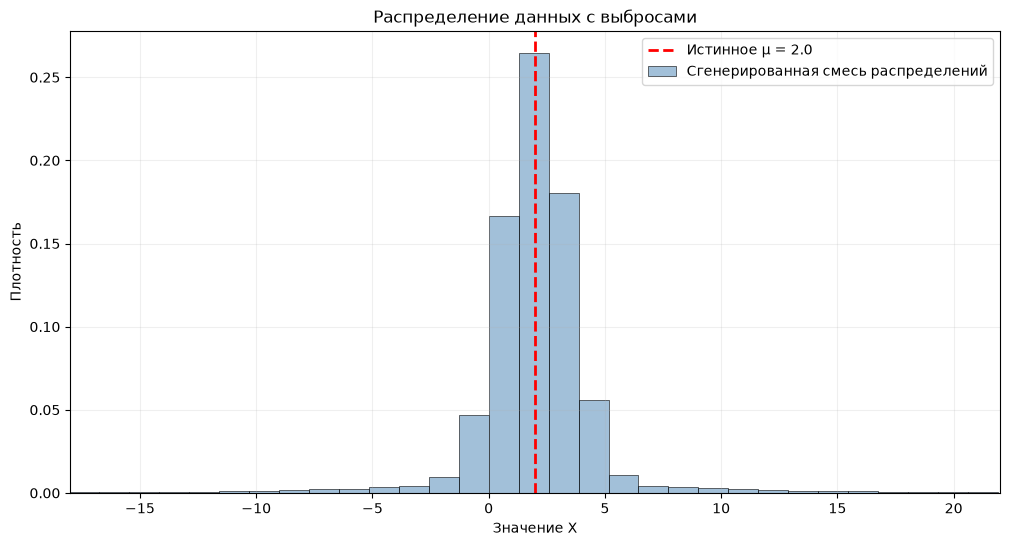

In [6]:
plt.figure(figsize=(12, 6))

sns.histplot(
    x,
    bins=150,
    stat="density",
    color="steelblue",
    alpha=0.5,
    label="Сгенерированная смесь распределений",
)

plt.axvline(
    mu,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Истинное μ = {mu}",
)

plt.xlim(mu - 20, mu + 20)
plt.xlabel("Значение X")
plt.ylabel("Плотность")
plt.title("Распределение данных с выбросами")
plt.legend()
plt.grid(alpha=0.2)
plt.show()